In [12]:
import optuna
from optuna.importance import get_param_importances, PedAnovaImportanceEvaluator

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [13]:
optuna.get_all_study_names("sqlite:///../database.db")

['ablation only molformer',
 'ablation only molecular descriptors',
 'ablation no film',
 'species specific Staphylococcus aureus',
 'species specific Salmonella enterica subsp. enterica serovar Typhimurium',
 'species specific Escherichia coli',
 'species specific Mycolicibacterium smegmatis',
 'species specific Streptococcus mutans',
 'species specific Raoultella planticola',
 'species specific Bacillus subtilis',
 'species specific Pseudoalteromonas ulvae',
 'ablation no organism',
 'model_optimization',
 'model_optimization_loop_2',
 'model_optimization_biased']

In [14]:
study = optuna.load_study(
    study_name="model_optimization_biased",
    storage="sqlite:///../database.db"
)

In [15]:
importances = get_param_importances(
    study,
    evaluator=PedAnovaImportanceEvaluator(),
    target=lambda t: t.value
)

importances

/tmp/ipykernel_13322/1418250384.py:3: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator=PedAnovaImportanceEvaluator(),
/home/sfcb/anaconda3/envs/antibiofilm/lib/python3.13/site-packages/optuna/importance/_ped_anova/evaluator.py:148: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  warnings.warn(


{'dropout': 0.18371215529369891,
 'log2_embed_size': 0.17528116520190745,
 'lr': 0.17102614472514485,
 'num_layers': 0.17057194092224287,
 'epochs': 0.15162767631225516,
 'log2_layer_0': 0.10348874475080129,
 'activation_1': 0.025864101379569522,
 'final_activation': 0.014201572997789447,
 'scheduler': 0.0042264984165904474}

In [16]:
data = pd.DataFrame(
        list(importances.items()),
        columns=["hyperparameter", "importance"]
      ).sort_values("importance", ascending=False)
data.set_index("hyperparameter", inplace=True)
data

,importance
hyperparameter,
dropout,0.183712
log2_embed_size,0.175281
lr,0.171026
num_layers,0.170572
epochs,0.151628
log2_layer_0,0.103489
activation_1,0.025864
final_activation,0.014202
scheduler,0.004226


<Axes: ylabel='hyperparameter'>

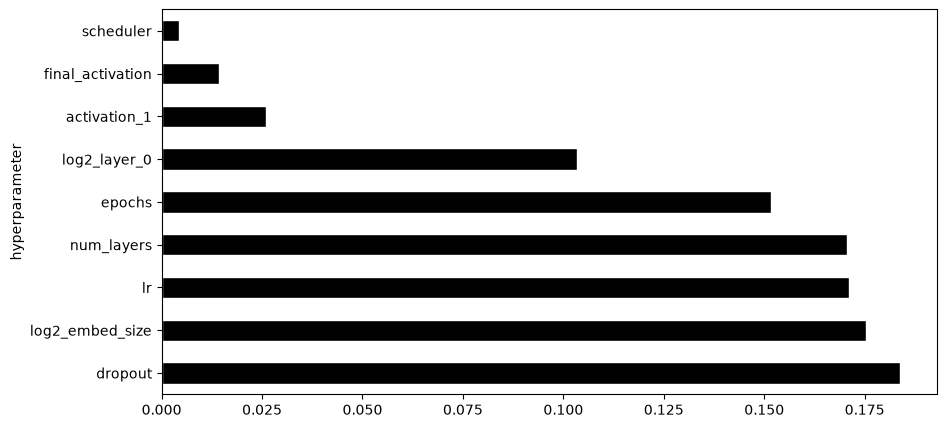

In [17]:
plt.figure(figsize=(10,5))
data.importance.plot(kind="barh", colormap = "gist_gray", edgecolor="white")

In [18]:
df = pd.DataFrame([{"number": t.number, "value": t.value, **t.params} for t in study.get_trials()])
df.head()

,number,value,log2_embed_size,num_layers,log2_layer_0,activation_1,final_activation,elu_alpha,dropout,lr,...,log2_layer_3,activation_4,log2_layer_4,activation_5,schel_step_size,schel_t_max_mod,shchel_eta_min,log2_layer_5,activation_6,lRelu_slope
0,0,2.887454,4,1,6,sigmoid,elu,0.385392,0.193030,0.000018,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1.359475,9,5,4,tanh,sigmoid,NaN,0.399477,0.000019,...,5.0,identity,9.0,gelu,15.0,NaN,NaN,NaN,NaN,NaN
2,2,1.192701,11,5,4,leaky_relu,identity,NaN,0.371731,0.006576,...,8.0,identity,12.0,identity,25.0,NaN,NaN,NaN,NaN,NaN
3,3,0.902848,9,4,11,leaky_relu,elu,1.460162,0.401667,0.000207,...,7.0,sigmoid,NaN,NaN,30.0,NaN,NaN,NaN,NaN,NaN
4,4,0.898805,10,3,5,tanh,elu,1.501199,0.310810,0.000043,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
df.loc[df.number.eq(926), "value"]

926    0.81742
Name: value, dtype: float64

In [20]:
df.value.min()

np.float64(0.817420162967613)

In [21]:
df["FiLM layer size"] = 2**df.log2_embed_size

Text(0.5, 1.0, 'C')

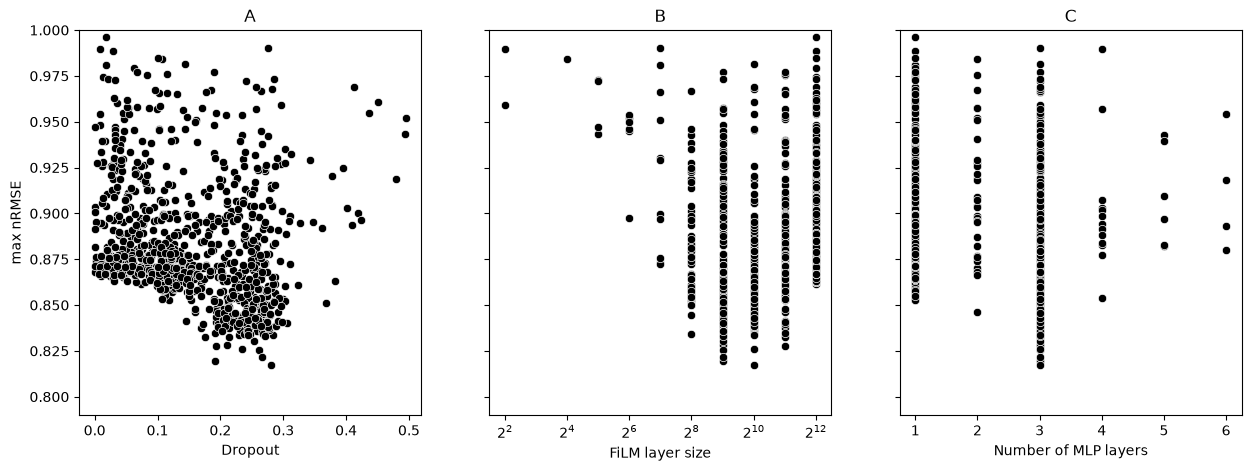

In [22]:
fig,(ax1,ax2,ax3) = plt.subplots(ncols=3, sharey=True, figsize=(15,5))
sns.scatterplot(df[df.value<1], x="dropout", y="value", color="black", ax=ax1)
ax1.set_ylim(top = 1, bottom=0.79)
ax1.set_xlabel("Dropout")
ax1.set_ylabel("max nRMSE")
ax1.set_title("A")

sns.scatterplot(df[df.value>0], x="FiLM layer size", y="value", color="black", ax=ax2)
ax2.set_xscale("log", base=2)
ax2.set_title("B")

sns.scatterplot(df[df.value>0], x="num_layers", y="value", color="black", ax=ax3)
ax3.set_xlabel("Number of MLP layers")
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))
ax3.set_title("C")
